<a href="https://colab.research.google.com/github/davidhoky/Deep-Learning/blob/main/DL_2802501306_GSLC1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Deep Learning GSLC
#Sesi 05: Transfer Learning untuk Klasifikasi Citra dengan Data Terbatas




## 0. Setup, seed, dan konfigurasi

In [1]:
import os, random, time, json, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)

# Konfigurasi protokol
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 5            # early stopping pada validation loss
WEIGHT_DECAY = 1e-2
NUM_CLASSES = 10
DATA_ROOT = "data"
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

CAT_BREEDS = ["abyssinian", "bengal", "birman", "bombay", "british shorthair"]
DOG_BREEDS = ["american bulldog", "beagle", "boxer", "chihuahua", "pug"]

Device: cuda | torch 2.11.0+cu130


## 1. Dataset: Oxford-IIIT Pet (subset 10 kelas) dan split stratified 70/15/15

In [2]:
ds_a = datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", download=True)
ds_b = datasets.OxfordIIITPet(DATA_ROOT, split="test", target_types="category", download=True)

all_paths = list(ds_a._images) + list(ds_b._images)
all_labels = list(ds_a._labels) + list(ds_b._labels)
classes = ds_a.classes
name_to_idx = {c.lower(): i for i, c in enumerate(classes)}

wanted = CAT_BREEDS + DOG_BREEDS
missing = [n for n in wanted if n not in name_to_idx]
assert not missing, f"Nama kelas tidak ditemukan: {missing}. Cek ds_a.classes"

selected = [name_to_idx[n] for n in wanted]
remap = {old: new for new, old in enumerate(selected)}
class_names = [classes[i] for i in selected]

paths = [p for p, l in zip(all_paths, all_labels) if l in remap]
labels = np.array([remap[l] for l in all_labels if l in remap])
paths = np.array(paths, dtype=object)
print("Total citra subset:", len(paths))
print(pd.Series(labels).map(lambda i: class_names[i]).value_counts())

idx = np.arange(len(paths))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=labels[temp_idx], random_state=SEED)
print(f"train={len(train_idx)} val={len(val_idx)} test={len(test_idx)}")

# Cek data leakage
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))

100%|██████████| 792M/792M [00:35<00:00, 22.3MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.7MB/s]


Total citra subset: 1981
American Bulldog     200
Beagle               200
Pug                  200
Bengal               200
Birman               200
British Shorthair    200
Chihuahua            200
Boxer                199
Abyssinian           198
Bombay               184
Name: count, dtype: int64
train=1386 val=297 test=298


## 2. Transformasi data (augmentasi hanya untuk train) dan DataLoader

In [3]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
MEAN, STD = weights.transforms().mean, weights.transforms().std

# Tanpa augmentasi / evaluasi: deterministik
plain_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_tf = plain_tf

# Dengan augmentasi (hanya pada train set)
aug_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class PetDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), int(self.labels[i])

def seed_worker(worker_id):
    s = SEED + worker_id
    np.random.seed(s)
    random.seed(s)

def make_loaders(use_aug):
    g = torch.Generator()
    g.manual_seed(SEED)
    train_ds = PetDS(paths[train_idx], labels[train_idx], aug_tf if use_aug else plain_tf)
    val_ds = PetDS(paths[val_idx], labels[val_idx], eval_tf)
    test_ds = PetDS(paths[test_idx], labels[test_idx], eval_tf)
    kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True, worker_init_fn=seed_worker)
    return (DataLoader(train_ds, shuffle=True, generator=g, **kw),
            DataLoader(val_ds, shuffle=False, **kw),
            DataLoader(test_ds, shuffle=False, **kw))

## 3. Model builder, utilitas training, dan evaluasi

In [4]:
def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

def freeze_all(model):
    for p in model.parameters():
        p.requires_grad = False

def build_model(mode):
    # Mengembalikan (model, param_groups, deskripsi_lr). Seed diset ulang agar inisialisasi head konsisten.
    set_seed()
    if mode == "B1":      # from scratch
        m = models.resnet18(weights=None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        groups = [{"params": m.parameters(), "lr": 1e-3}]
        lr_desc = "all=1e-3"
    elif mode == "B2":    # feature extraction
        m = models.resnet18(weights=weights)
        freeze_all(m)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)   # dibuat setelah freeze, jadi trainable
        groups = [{"params": m.fc.parameters(), "lr": 1e-3}]
        lr_desc = "fc=1e-3"
    elif mode == "B3":    # progressive fine-tuning (layer4 + fc)
        m = models.resnet18(weights=weights)
        freeze_all(m)
        for p in m.layer4.parameters():
            p.requires_grad = True
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        groups = [{"params": m.layer4.parameters(), "lr": 1e-4},
                  {"params": m.fc.parameters(), "lr": 1e-3}]
        lr_desc = "layer4=1e-4; fc=1e-3"
    elif mode == "B5":    # EfficientNet-B0 (bonus), strategi analog B3
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        freeze_all(m)
        for blk in m.features[-2:]:
            for p in blk.parameters():
                p.requires_grad = True
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        groups = [{"params": [p for blk in m.features[-2:] for p in blk.parameters()], "lr": 1e-4},
                  {"params": m.classifier.parameters(), "lr": 1e-3}]
        lr_desc = "features[-2:]=1e-4; classifier=1e-3"
    else:
        raise ValueError(mode)
    return m.to(device), groups, lr_desc

def set_train_mode(model):
    # BatchNorm pada lapisan beku dijaga di mode eval agar running statistics pretrained tidak berubah
    model.train()
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            if all(not p.requires_grad for p in mod.parameters(recurse=False)):
                mod.eval()

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    if training:
        set_train_mode(model)
    else:
        model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        out = model(x.to(device))
        pr = torch.softmax(out, 1).cpu()
        ys.append(y); ps.append(pr.argmax(1)); probs.append(pr)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()

RESULTS = []
MODELS = {}

def train_experiment(name, mode, use_aug, strategy):
    model, groups, lr_desc = build_model(mode)
    trainable, total = count_params(model)
    print(f"[{name}] trainable params: {trainable:,} / {total:,}")   # verifikasi sebelum optimizer dibuat

    train_loader, val_loader, test_loader = make_loaders(use_aug)
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()

    hist, best = [], {"val_loss": float("inf"), "state": None, "epoch": 0, "train_acc": None, "val_acc": None}
    wait = 0
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        hist.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
        print(f"  ep{epoch:02d} train_loss={tr_loss:.4f} acc={tr_acc:.3f} | val_loss={va_loss:.4f} acc={va_acc:.3f}")
        if va_loss < best["val_loss"] - 1e-4:
            best.update(val_loss=va_loss, state=copy.deepcopy(model.state_dict()), epoch=epoch,
                        train_acc=tr_acc, val_acc=va_acc)
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"  early stopping di epoch {epoch}")
                break
    if device.type == "cuda":
        torch.cuda.synchronize()
    duration = time.time() - t0

    model.load_state_dict(best["state"])
    y, p, _ = predict(model, test_loader)
    rec = dict(
        experiment=name, strategy=strategy, architecture=("EfficientNet-B0" if mode == "B5" else "ResNet-18"),
        augmentation=use_aug, trainable_params=trainable, total_params=total, learning_rate=lr_desc,
        best_epoch=best["epoch"], epochs_run=len(hist), train_time_sec=round(duration, 1),
        train_acc_at_best=best["train_acc"], val_acc=best["val_acc"], val_loss=best["val_loss"],
        gap_train_minus_val=best["train_acc"] - best["val_acc"],
        test_acc=accuracy_score(y, p), test_macro_f1=f1_score(y, p, average="macro"), seed=SEED,
    )
    RESULTS.append(rec)
    MODELS[name] = model
    pd.DataFrame(hist).to_csv(f"{OUT_DIR}/history_{name}.csv", index=False)
    print(json.dumps(rec, indent=2, default=float))
    return rec

## 4. Eksperimen

### B1: Baseline from scratch

In [5]:
train_experiment("B1_scratch", "B1", use_aug=True, strategy="Training from scratch")

[B1_scratch] trainable params: 11,181,642 / 11,181,642
  ep01 train_loss=2.2677 acc=0.208 | val_loss=2.3172 acc=0.222
  ep02 train_loss=1.9614 acc=0.316 | val_loss=2.2138 acc=0.266
  ep03 train_loss=1.9063 acc=0.323 | val_loss=2.0377 acc=0.330
  ep04 train_loss=1.7593 acc=0.369 | val_loss=2.1807 acc=0.320
  ep05 train_loss=1.6976 acc=0.407 | val_loss=2.0884 acc=0.330
  ep06 train_loss=1.5784 acc=0.450 | val_loss=2.0199 acc=0.337
  ep07 train_loss=1.5422 acc=0.466 | val_loss=2.2447 acc=0.337
  ep08 train_loss=1.4004 acc=0.507 | val_loss=1.8076 acc=0.458
  ep09 train_loss=1.3725 acc=0.539 | val_loss=1.9317 acc=0.380
  ep10 train_loss=1.3050 acc=0.553 | val_loss=1.8118 acc=0.431
  ep11 train_loss=1.2674 acc=0.560 | val_loss=1.8855 acc=0.404
  ep12 train_loss=1.1371 acc=0.606 | val_loss=2.4305 acc=0.337
  ep13 train_loss=1.0819 acc=0.624 | val_loss=1.3606 acc=0.545
  ep14 train_loss=0.9961 acc=0.651 | val_loss=1.5700 acc=0.488
  ep15 train_loss=0.9925 acc=0.665 | val_loss=1.4899 acc=0.576


{'experiment': 'B1_scratch',
 'strategy': 'Training from scratch',
 'architecture': 'ResNet-18',
 'augmentation': True,
 'trainable_params': 11181642,
 'total_params': 11181642,
 'learning_rate': 'all=1e-3',
 'best_epoch': 25,
 'epochs_run': 30,
 'train_time_sec': 447.9,
 'train_acc_at_best': 0.8217893217893217,
 'val_acc': 0.6195286195286195,
 'val_loss': 1.268686507888113,
 'gap_train_minus_val': 0.20226070226070225,
 'test_acc': 0.610738255033557,
 'test_macro_f1': 0.6055295329221491,
 'seed': 42}

### B2: Feature extraction

In [6]:
rec_b2 = train_experiment("B2_feature_extraction", "B2", use_aug=True, strategy="Feature extraction (backbone beku)")
assert rec_b2["trainable_params"] == 5130, "Trainable params B2 seharusnya 5.130"

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


[B2_feature_extraction] trainable params: 5,130 / 11,181,642
  ep01 train_loss=1.3295 acc=0.615 | val_loss=0.6449 acc=0.875
  ep02 train_loss=0.4925 acc=0.916 | val_loss=0.3411 acc=0.960
  ep03 train_loss=0.3225 acc=0.945 | val_loss=0.2690 acc=0.953
  ep04 train_loss=0.2464 acc=0.953 | val_loss=0.2134 acc=0.960
  ep05 train_loss=0.2174 acc=0.957 | val_loss=0.1967 acc=0.960
  ep06 train_loss=0.1927 acc=0.961 | val_loss=0.1953 acc=0.939
  ep07 train_loss=0.1753 acc=0.968 | val_loss=0.1937 acc=0.956
  ep08 train_loss=0.1571 acc=0.967 | val_loss=0.1665 acc=0.956
  ep09 train_loss=0.1428 acc=0.966 | val_loss=0.1648 acc=0.960
  ep10 train_loss=0.1304 acc=0.975 | val_loss=0.1645 acc=0.960
  ep11 train_loss=0.1263 acc=0.973 | val_loss=0.1783 acc=0.943
  ep12 train_loss=0.1230 acc=0.973 | val_loss=0.1514 acc=0.946
  ep13 train_loss=0.1186 acc=0.970 | val_loss=0.1458 acc=0.956
  ep14 train_loss=0.1120 acc=0.972 | val_loss=0.1638 acc=0.949
  ep15 train_loss=0.0959 acc=0.980 | val_loss=0.1615 acc=

### B3: Progressive fine-tuning (layer4 + fc, differential learning rate)

In [7]:
train_experiment("B3_finetune_layer4", "B3", use_aug=True, strategy="Fine-tuning layer4 + fc")

[B3_finetune_layer4] trainable params: 8,398,858 / 11,181,642
  ep01 train_loss=0.7144 acc=0.797 | val_loss=0.1725 acc=0.943
  ep02 train_loss=0.1463 acc=0.968 | val_loss=0.1800 acc=0.946
  ep03 train_loss=0.0922 acc=0.977 | val_loss=0.1785 acc=0.949
  ep04 train_loss=0.0626 acc=0.983 | val_loss=0.1295 acc=0.963
  ep05 train_loss=0.0394 acc=0.991 | val_loss=0.1546 acc=0.956
  ep06 train_loss=0.0308 acc=0.994 | val_loss=0.1535 acc=0.960
  ep07 train_loss=0.0255 acc=0.994 | val_loss=0.1680 acc=0.949
  ep08 train_loss=0.0143 acc=0.999 | val_loss=0.2182 acc=0.939
  ep09 train_loss=0.0185 acc=0.994 | val_loss=0.1557 acc=0.949
  early stopping di epoch 9
{
  "experiment": "B3_finetune_layer4",
  "strategy": "Fine-tuning layer4 + fc",
  "architecture": "ResNet-18",
  "augmentation": true,
  "trainable_params": 8398858,
  "total_params": 11181642,
  "learning_rate": "layer4=1e-4; fc=1e-3",
  "best_epoch": 4,
  "epochs_run": 9,
  "train_time_sec": 121.7,
  "train_acc_at_best": 0.982683982683982

{'experiment': 'B3_finetune_layer4',
 'strategy': 'Fine-tuning layer4 + fc',
 'architecture': 'ResNet-18',
 'augmentation': True,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'learning_rate': 'layer4=1e-4; fc=1e-3',
 'best_epoch': 4,
 'epochs_run': 9,
 'train_time_sec': 121.7,
 'train_acc_at_best': 0.9826839826839827,
 'val_acc': 0.9629629629629629,
 'val_loss': 0.12952155225380302,
 'gap_train_minus_val': 0.019721019721019806,
 'test_acc': 0.9530201342281879,
 'test_macro_f1': 0.9529682484870825,
 'seed': 42}

### B4: Uji kontrol augmentasi (konfigurasi B3 tanpa augmentasi vs dengan augmentasi)

In [8]:
# 'Dengan augmentasi' = B3 di atas. Di sini dijalankan versi tanpa augmentasi dengan konfigurasi identik.
train_experiment("B4_finetune_noaug", "B3", use_aug=False, strategy="Fine-tuning layer4 + fc (tanpa augmentasi)")

[B4_finetune_noaug] trainable params: 8,398,858 / 11,181,642
  ep01 train_loss=0.6271 acc=0.824 | val_loss=0.1515 acc=0.976
  ep02 train_loss=0.0693 acc=0.987 | val_loss=0.1554 acc=0.963
  ep03 train_loss=0.0242 acc=0.999 | val_loss=0.1295 acc=0.966
  ep04 train_loss=0.0151 acc=1.000 | val_loss=0.1147 acc=0.970
  ep05 train_loss=0.0086 acc=1.000 | val_loss=0.1432 acc=0.963
  ep06 train_loss=0.0045 acc=1.000 | val_loss=0.1282 acc=0.966
  ep07 train_loss=0.0034 acc=1.000 | val_loss=0.1212 acc=0.973
  ep08 train_loss=0.0024 acc=1.000 | val_loss=0.1244 acc=0.970
  ep09 train_loss=0.0024 acc=1.000 | val_loss=0.1231 acc=0.973
  early stopping di epoch 9
{
  "experiment": "B4_finetune_noaug",
  "strategy": "Fine-tuning layer4 + fc (tanpa augmentasi)",
  "architecture": "ResNet-18",
  "augmentation": false,
  "trainable_params": 8398858,
  "total_params": 11181642,
  "learning_rate": "layer4=1e-4; fc=1e-3",
  "best_epoch": 4,
  "epochs_run": 9,
  "train_time_sec": 81.4,
  "train_acc_at_best": 

{'experiment': 'B4_finetune_noaug',
 'strategy': 'Fine-tuning layer4 + fc (tanpa augmentasi)',
 'architecture': 'ResNet-18',
 'augmentation': False,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'learning_rate': 'layer4=1e-4; fc=1e-3',
 'best_epoch': 4,
 'epochs_run': 9,
 'train_time_sec': 81.4,
 'train_acc_at_best': 1.0,
 'val_acc': 0.9696969696969697,
 'val_loss': 0.11473852451827991,
 'gap_train_minus_val': 0.030303030303030276,
 'test_acc': 0.9563758389261745,
 'test_macro_f1': 0.9562608613173609,
 'seed': 42}

### B5 (Bonus): EfficientNet-B0

In [9]:
RUN_B5 = True
if RUN_B5:
    train_experiment("B5_efficientnet_b0", "B5", use_aug=True, strategy="Fine-tuning blok akhir EfficientNet-B0")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s]


[B5_efficientnet_b0] trainable params: 1,142,202 / 4,020,358
  ep01 train_loss=1.0547 acc=0.792 | val_loss=0.2289 acc=0.953
  ep02 train_loss=0.2251 acc=0.952 | val_loss=0.1321 acc=0.970
  ep03 train_loss=0.1519 acc=0.970 | val_loss=0.1111 acc=0.973
  ep04 train_loss=0.1135 acc=0.966 | val_loss=0.0999 acc=0.973
  ep05 train_loss=0.0995 acc=0.973 | val_loss=0.1029 acc=0.976
  ep06 train_loss=0.0726 acc=0.981 | val_loss=0.0965 acc=0.976
  ep07 train_loss=0.0611 acc=0.984 | val_loss=0.1053 acc=0.973
  ep08 train_loss=0.0425 acc=0.991 | val_loss=0.1081 acc=0.973
  ep09 train_loss=0.0494 acc=0.988 | val_loss=0.0977 acc=0.973
  ep10 train_loss=0.0405 acc=0.991 | val_loss=0.1027 acc=0.973
  ep11 train_loss=0.0369 acc=0.994 | val_loss=0.1052 acc=0.970
  early stopping di epoch 11
{
  "experiment": "B5_efficientnet_b0",
  "strategy": "Fine-tuning blok akhir EfficientNet-B0",
  "architecture": "EfficientNet-B0",
  "augmentation": true,
  "trainable_params": 1142202,
  "total_params": 4020358,
  

## 5. Tabel konsolidasi dan penyimpanan log mentah

In [10]:
df = pd.DataFrame(RESULTS)
df.to_csv(f"{OUT_DIR}/metrics_summary.csv", index=False)
with open(f"{OUT_DIR}/metrics_summary.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
df[["experiment", "strategy", "trainable_params", "learning_rate", "best_epoch", "train_time_sec",
    "train_acc_at_best", "val_acc", "gap_train_minus_val", "test_acc", "test_macro_f1"]].round(4)

,experiment,strategy,trainable_params,learning_rate,best_epoch,train_time_sec,train_acc_at_best,val_acc,gap_train_minus_val,test_acc,test_macro_f1
0,B1_scratch,Training from scratch,11181642,all=1e-3,25,447.9,0.8218,0.6195,0.2023,0.6107,0.6055
1,B2_feature_extraction,Feature extraction (backbone beku),5130,fc=1e-3,22,375.7,0.9762,0.9562,0.0200,0.9664,0.9667
2,B3_finetune_layer4,Fine-tuning layer4 + fc,8398858,layer4=1e-4; fc=1e-3,4,121.7,0.9827,0.9630,0.0197,0.9530,0.9530
3,B4_finetune_noaug,Fine-tuning layer4 + fc (tanpa augmentasi),8398858,layer4=1e-4; fc=1e-3,4,81.4,1.0000,0.9697,0.0303,0.9564,0.9563
4,B5_efficientnet_b0,Fine-tuning blok akhir EfficientNet-B0,1142202,features[-2:]=1e-4; classifier=1e-3,6,146.9,0.9812,0.9764,0.0048,0.9664,0.9664


## 6. Kurva training vs validation loss (B1, B2, B3)

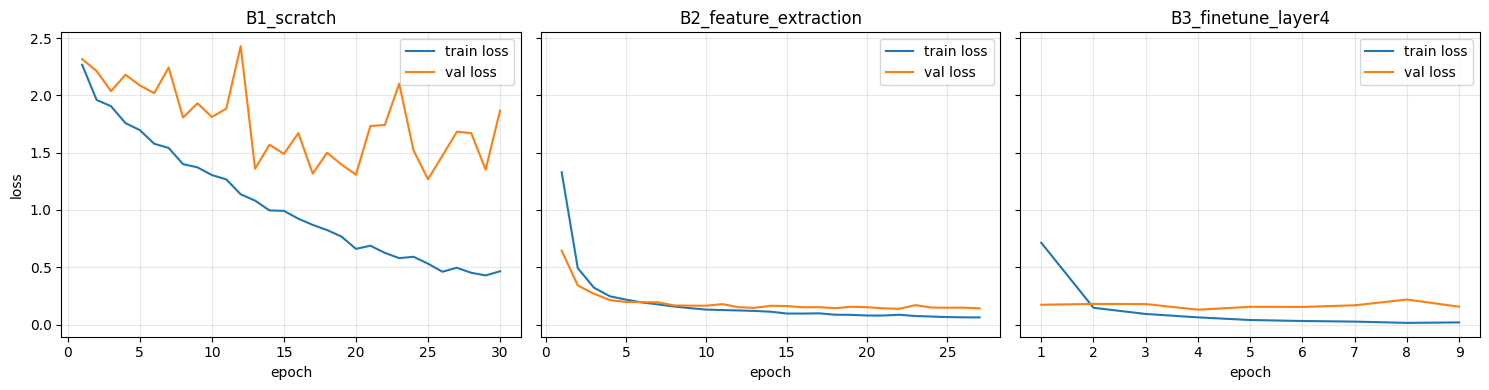

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, ["B1_scratch", "B2_feature_extraction", "B3_finetune_layer4"]):
    h = pd.read_csv(f"{OUT_DIR}/history_{name}.csv")
    ax.plot(h["epoch"], h["train_loss"], label="train loss")
    ax.plot(h["epoch"], h["val_loss"], label="val loss")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curves_B1_B2_B3.png", dpi=150)
plt.show()

## 7. Failure analysis (model terbaik dipilih berdasarkan **validation**, bukan test)

Model terbaik (berdasarkan val_acc): B3_finetune_layer4
Salah prediksi: 14 dari 298


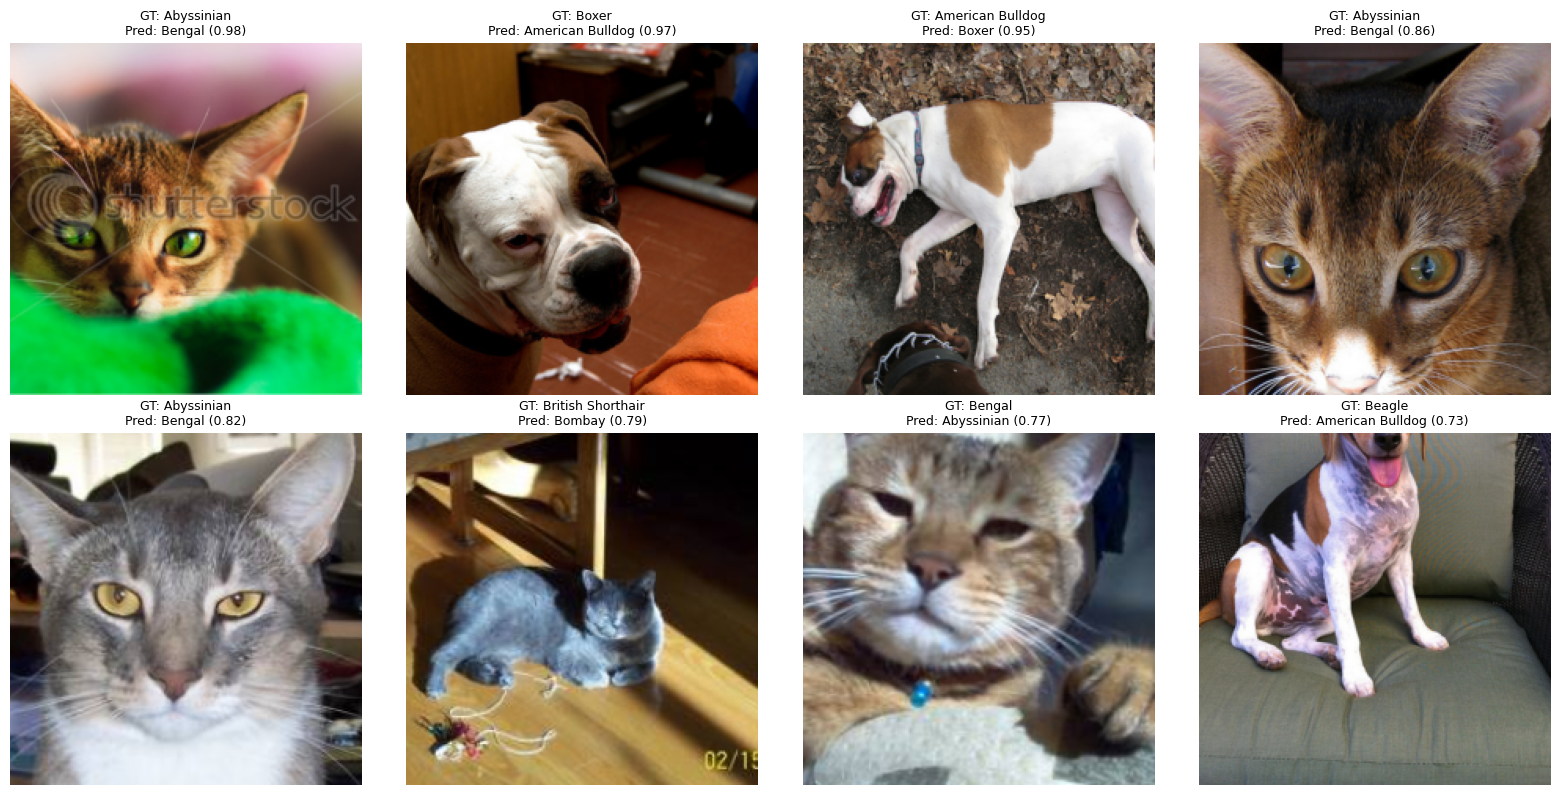

,test_index,file,ground_truth,prediction,confidence
0,127,data/oxford-iiit-pet/images/Abyssinian_101.jpg,Abyssinian,Bengal,0.978080
1,74,data/oxford-iiit-pet/images/boxer_2.jpg,Boxer,American Bulldog,0.969568
2,182,data/oxford-iiit-pet/images/american_bulldog_1...,American Bulldog,Boxer,0.954654
3,175,data/oxford-iiit-pet/images/Abyssinian_90.jpg,Abyssinian,Bengal,0.860945
4,98,data/oxford-iiit-pet/images/Abyssinian_221.jpg,Abyssinian,Bengal,0.824315
5,55,data/oxford-iiit-pet/images/British_Shorthair_...,British Shorthair,Bombay,0.792255
6,198,data/oxford-iiit-pet/images/Bengal_143.jpg,Bengal,Abyssinian,0.767823
7,48,data/oxford-iiit-pet/images/beagle_64.jpg,Beagle,American Bulldog,0.727959


In [12]:
cand = [r for r in RESULTS if r["architecture"] == "ResNet-18" and r["augmentation"]] or RESULTS
best_name = max(cand, key=lambda r: r["val_acc"])["experiment"]
print("Model terbaik (berdasarkan val_acc):", best_name)
best_model = MODELS[best_name]

test_ds = PetDS(paths[test_idx], labels[test_idx], eval_tf)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
y, p, probs = predict(best_model, test_loader)
wrong = np.where(y != p)[0]
print(f"Salah prediksi: {len(wrong)} dari {len(y)}")

# Urutkan dari confidence tertinggi (kesalahan paling "yakin")
wrong = sorted(wrong, key=lambda i: -probs[i].max())
show = wrong[:8]

def denorm(x):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (x * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

rows = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(denorm(test_ds[i][0])); ax.axis("off")
    ax.set_title(f"GT: {class_names[y[i]]}\nPred: {class_names[p[i]]} ({probs[i].max():.2f})", fontsize=9)
    rows.append(dict(test_index=int(i), file=str(paths[test_idx][i]), ground_truth=class_names[y[i]],
                     prediction=class_names[p[i]], confidence=float(probs[i].max())))
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/failure_analysis.png", dpi=150)
plt.show()
pd.DataFrame(rows).to_csv(f"{OUT_DIR}/failure_cases.csv", index=False)
pd.DataFrame(rows)

## 8. (Opsional, C5) Grad-CAM pada layer4: sebelum (B2) vs sesudah fine-tuning (B3)

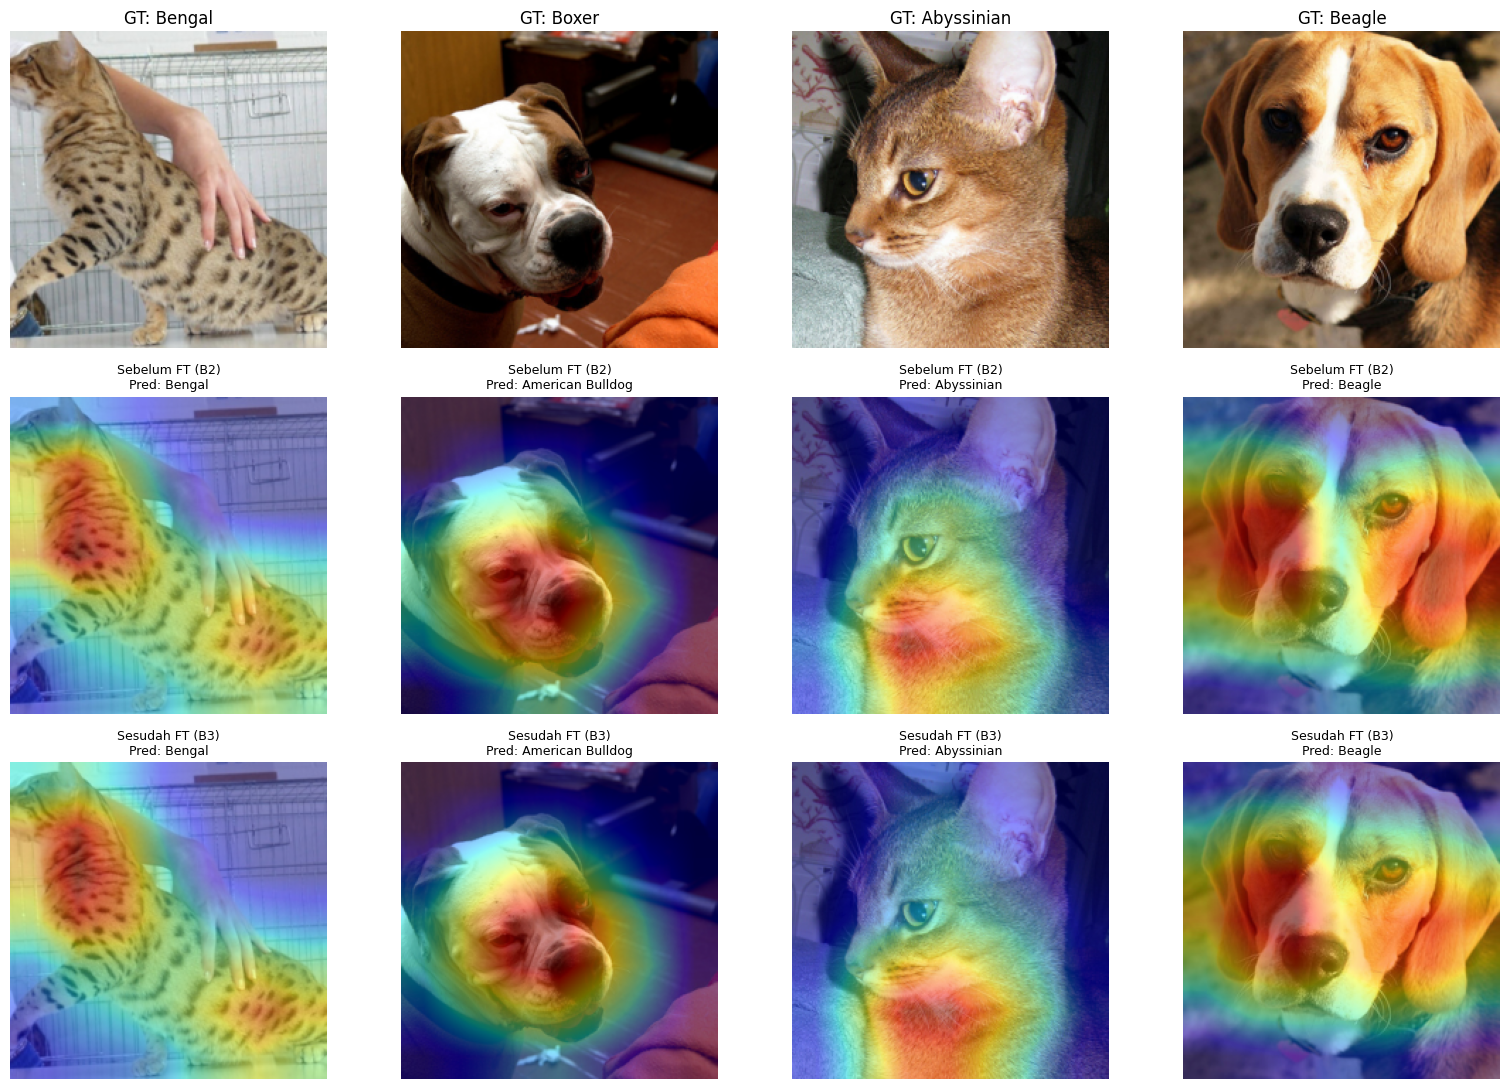

In [13]:
import torch.nn.functional as F

def gradcam(model, x):
    store = {}
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = model.layer4.register_forward_hook(fwd_hook)
    model.eval()
    x = x.unsqueeze(0).to(device).clone().requires_grad_(True)   # agar grafik gradien tetap ada pada model beku
    out = model(x)
    cls = out.argmax(1).item()
    model.zero_grad()
    out[0, cls].backward()
    h.remove()
    w = store["g"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy(), cls

sample_ids = list(range(0, len(test_ds), max(1, len(test_ds) // 4)))[:4]
fig, axes = plt.subplots(3, len(sample_ids), figsize=(4 * len(sample_ids), 11))
for j, i in enumerate(sample_ids):
    x, yi = test_ds[i]
    img = denorm(x)
    axes[0, j].imshow(img); axes[0, j].set_title(f"GT: {class_names[yi]}"); axes[0, j].axis("off")
    for r, (nm, lbl) in enumerate([("B2_feature_extraction", "Sebelum FT (B2)"), ("B3_finetune_layer4", "Sesudah FT (B3)")], start=1):
        cam, cls = gradcam(MODELS[nm], x)
        axes[r, j].imshow(img); axes[r, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[r, j].set_title(f"{lbl}\nPred: {class_names[cls]}", fontsize=9); axes[r, j].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/gradcam_layer4.png", dpi=150)
plt.show()

In [14]:
#download result
!zip -r results.zip results

  adding: results/ (stored 0%)
  adding: results/gradcam_layer4.png (deflated 0%)
  adding: results/failure_cases.csv (deflated 58%)
  adding: results/history_B2_feature_extraction.csv (deflated 63%)
  adding: results/history_B5_efficientnet_b0.csv (deflated 60%)
  adding: results/history_B3_finetune_layer4.csv (deflated 57%)
  adding: results/failure_analysis.png (deflated 0%)
  adding: results/history_B4_finetune_noaug.csv (deflated 55%)
  adding: results/history_B1_scratch.csv (deflated 58%)
  adding: results/metrics_summary.csv (deflated 51%)
  adding: results/loss_curves_B1_B2_B3.png (deflated 8%)
  adding: results/metrics_summary.json (deflated 74%)


Semua artefak terdapat dalam folder `results/`: `metrics_summary.csv/json`, `history_*.csv`, `loss_curves_B1_B2_B3.png`, `failure_analysis.png`, `failure_cases.csv`, `gradcam_layer4.png`.

